In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset Shape:", X.shape)
print("Target Classes:", list(wine.target_names))
display(X.head())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

Dataset Shape: (178, 13)
Target Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
depths = range(1, 11)
train_acc_gini, test_acc_gini = [], []
train_acc_ent, test_acc_ent = [], []

for d in depths:
    dt_g = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42).fit(X_train, y_train)
    dt_e = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc_gini.append(accuracy_score(y_train, dt_g.predict(X_train)))
    test_acc_gini.append(accuracy_score(y_test, dt_g.predict(X_test)))
    train_acc_ent.append(accuracy_score(y_train, dt_e.predict(X_train)))
    test_acc_ent.append(accuracy_score(y_test, dt_e.predict(X_test)))

plt.figure(figsize=(8.5, 4.8))
plt.plot(depths, train_acc_gini, 'o--', color='#4F46E5', label='Train Acc (Gini)')
plt.plot(depths, test_acc_gini, 'o-', color='#0D9488', lw=2.2, label='Test Acc (Gini)')
plt.plot(depths, test_acc_ent, 's-', color='#D97706', lw=2.2, label='Test Acc (Entropy)')
plt.title('Effect of max_depth Pruning on Overfitting', fontweight='bold')
plt.xlabel('Tree Max Depth'); plt.ylabel('Accuracy'); plt.xticks(depths)
plt.legend(); plt.grid(True, alpha=0.4); plt.show()

Pruned Decision Tree Test Accuracy: 0.9111

Classification Report:
               precision    recall  f1-score   support

     class_0       0.83      1.00      0.91        15
     class_1       1.00      0.78      0.88        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.91        45
   macro avg       0.92      0.93      0.91        45
weighted avg       0.92      0.91      0.91        45



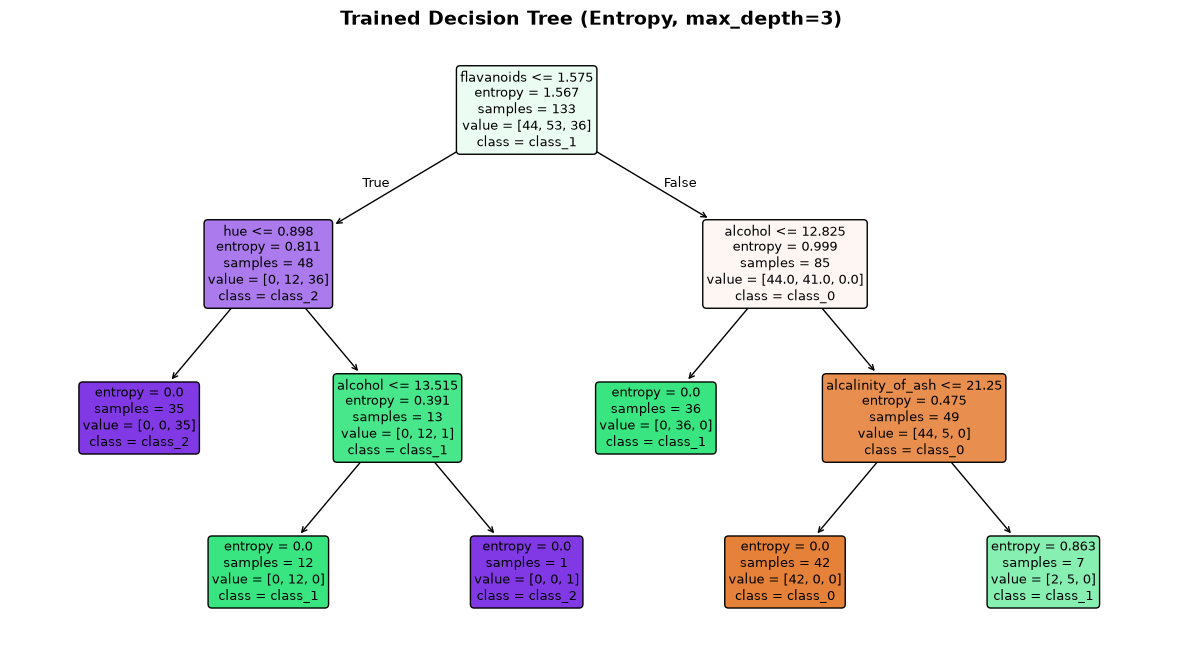

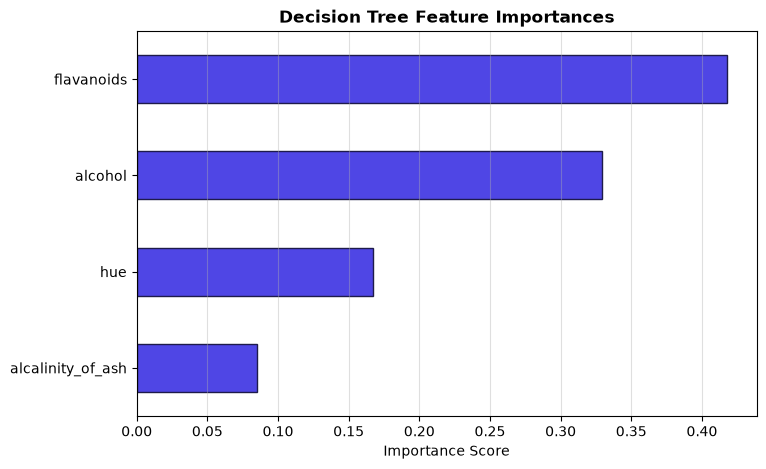

In [3]:
best_tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
best_tree.fit(X_train, y_train)
y_pred = best_tree.predict(X_test)

print(f"Pruned Decision Tree Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=wine.target_names))

# Visualize the Decision Tree
plt.figure(figsize=(15, 8))
plot_tree(best_tree, feature_names=wine.feature_names, class_names=wine.target_names,
          filled=True, rounded=True, fontsize=9)
plt.title('Trained Decision Tree (Entropy, max_depth=3)', fontsize=14, fontweight='bold')
plt.show()

# Feature Importances
imp = pd.Series(best_tree.feature_importances_, index=wine.feature_names).sort_values()
plt.figure(figsize=(8, 5))
imp[imp > 0].plot(kind='barh', color='#4F46E5', edgecolor='#1E1B4B')
plt.title('Decision Tree Feature Importances', fontweight='bold')
plt.xlabel('Importance Score')
plt.grid(True, axis='x', alpha=0.4)
plt.show()